# Predictive Maintenance of Aircraft Engines

## Remaining Useful Life (RUL) Prediction

**Dataset:** NASA C-MAPSS Turbofan Engine Dataset

### Project Objective
To predict the Remaining Useful Life of aircraft engines using sensor data and Machine Learning.

### Phase 1: Exploratory Data Analysis (EDA)
- Dataset Inspection
- Data Quality Analysis
- Statistical Analysis
- Sensor Analysis
- Data Visualization

In [2]:
%pip install matplotlib seaborn pandas numpy scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
columns = [
    'engine_id',
    'cycle',
    'setting_1',
    'setting_2',
    'setting_3'
]

columns += [f'sensor_{i}' for i in range(1, 22)]

print("Total Columns:", len(columns))
print(columns)

Total Columns: 26
['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [5]:
train = pd.read_csv(
    '../dataset/train_FD001.txt',
    sep=r'\s+',
    header=None,
    names=columns
)

train.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
print("Dataset Shape:", train.shape)

print("Total Engines:", train['engine_id'].nunique())

print("Total Sensors:", 21)

Dataset Shape: (20631, 26)
Total Engines: 100
Total Sensors: 21


In [7]:
train.head(10)

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,521.68,2388.03,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,518.67,642.48,1592.32,1397.77,14.62,...,522.32,2388.03,8132.32,8.3974,0.03,392,2388,100.0,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,518.67,642.56,1582.96,1400.97,14.62,...,522.47,2388.03,8131.07,8.4076,0.03,391,2388,100.0,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,518.67,642.12,1590.98,1394.80,14.62,...,521.79,2388.05,8125.69,8.3728,0.03,392,2388,100.0,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,518.67,641.71,1591.24,1400.46,14.62,...,521.79,2388.06,8129.38,8.4286,0.03,393,2388,100.0,38.95,23.4694


In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

In [9]:
train.describe()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


### DATA QUALITY ANALYSIS

In [10]:
missing_values = train.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
engine_id    0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

Total Missing Values: 0


In [11]:
print("Total Duplicate Rows:", train.duplicated().sum())

Total Duplicate Rows: 0


In [12]:
constant_columns = [
    col for col in train.columns
    if train[col].nunique() == 1
]

print("Constant Columns:")
print(constant_columns)

print("\nTotal Constant Columns:", len(constant_columns))

Constant Columns:
['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Total Constant Columns: 7


In [13]:
engine_cycles = train.groupby('engine_id')['cycle'].max()

print("Engine-wise Maximum Cycles:")
print(engine_cycles.head(10))

print("\nMinimum Engine Life:", engine_cycles.min())
print("Maximum Engine Life:", engine_cycles.max())
print("Average Engine Life:", engine_cycles.mean())

Engine-wise Maximum Cycles:
engine_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64

Minimum Engine Life: 128
Maximum Engine Life: 362
Average Engine Life: 206.31


### VISUAL EXPLORATORY DATA ANALYSIS

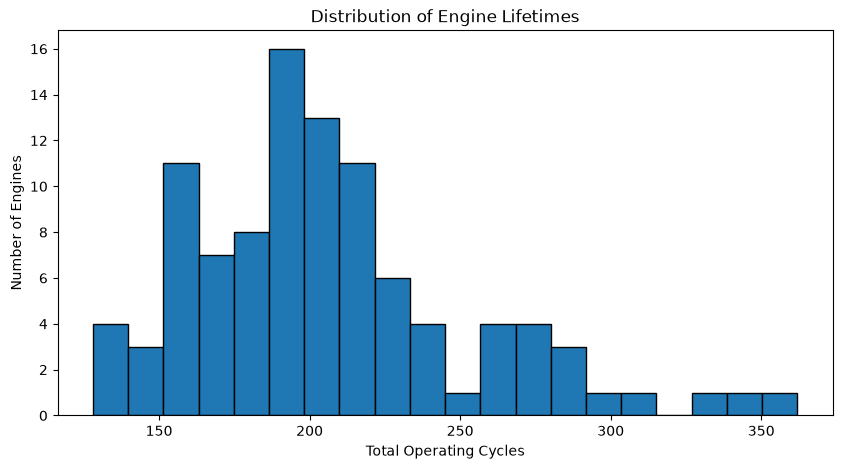

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(engine_cycles, bins=20, edgecolor='black')

plt.title('Distribution of Engine Lifetimes')
plt.xlabel('Total Operating Cycles')
plt.ylabel('Number of Engines')

plt.show()

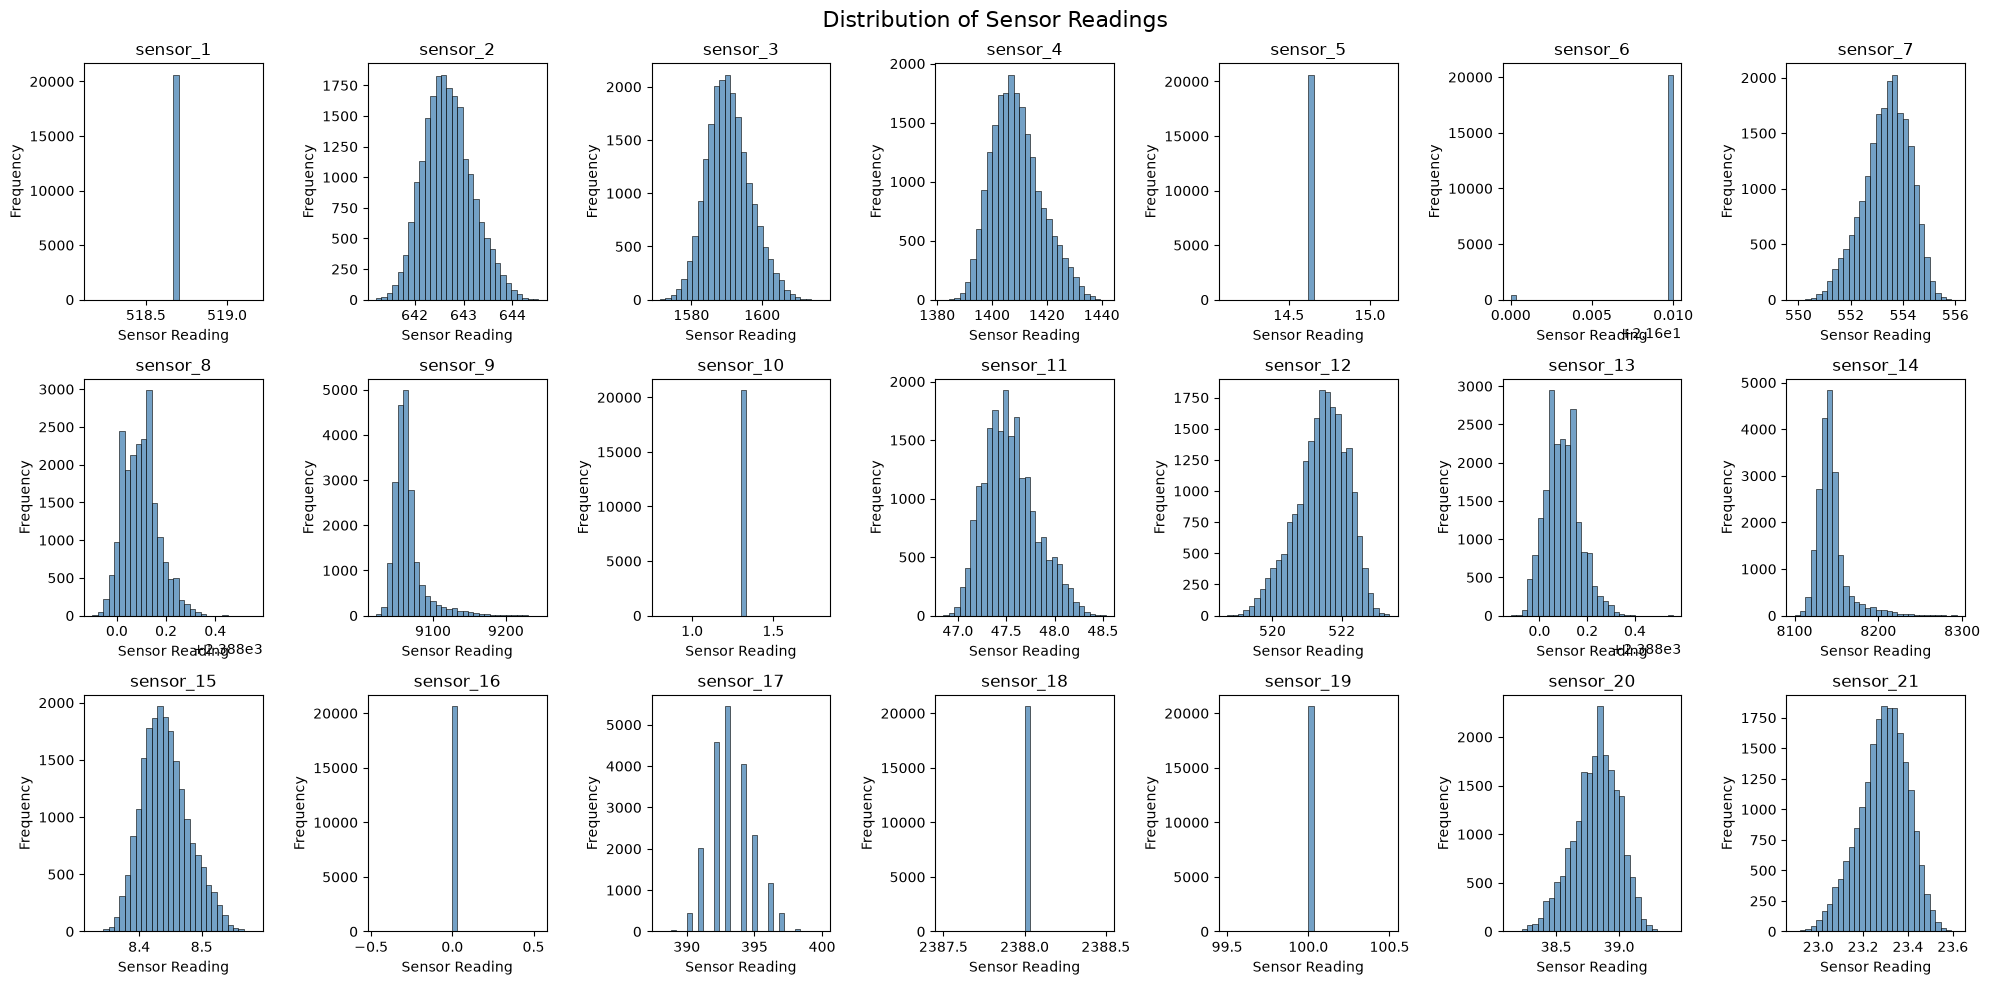

In [17]:
# Selecting all sensor columns
sensor_columns = [col for col in train.columns if col.startswith('sensor_')]

# Creating subplots for all 21 sensors
fig, axes = plt.subplots(3, 7, figsize=(20, 10))

# Flattening axes for easy iteration
axes = axes.flatten()

# Plotting histogram for each sensor
for i, sensor in enumerate(sensor_columns):

    sns.histplot(
        data=train,
        x=sensor,
        bins=30,
        ax=axes[i],
        color='steelblue'
    )

    axes[i].set_title(sensor)
    axes[i].set_xlabel('Sensor Reading')
    axes[i].set_ylabel('Frequency')

plt.suptitle('Distribution of Sensor Readings', fontsize=16)
plt.tight_layout()
plt.show()


### Observations – Sensor Distribution Analysis

1. Several sensors show approximately bell-shaped distributions.
2. Sensors 8, 9, 13 and 14 exhibit right-skewed distributions.
3. Sensors 1, 5, 10, 16, 18 and 19 show constant distributions.
4. Sensor 17 displays multiple peaks in its distribution.
5. Different sensors exhibit different statistical distribution patterns.

**Conclusion:**
Sensor readings have different distribution characteristics. Further analysis is required to understand their relationship with engine degradation and Remaining Useful Life (RUL).


### Observations – Sensor Boxplot Analysis

1. Multiple sensors contain observations outside their whisker boundaries.
2. Sensors 1, 5, 10, 16, 18 and 19 show constant distributions.
3. Sensors 9 and 14 exhibit several upper-end outliers.
4. Sensors 7, 15, 20 and 21 show outliers on both ends.
5. Sensor 17 has a relatively different distribution pattern.

**Conclusion:**

Boxplots reveal variations in sensor readings and potential outliers. These observations will help in understanding sensor behaviour and making informed preprocessing decisions.

Outliers will not be removed without further investigation.


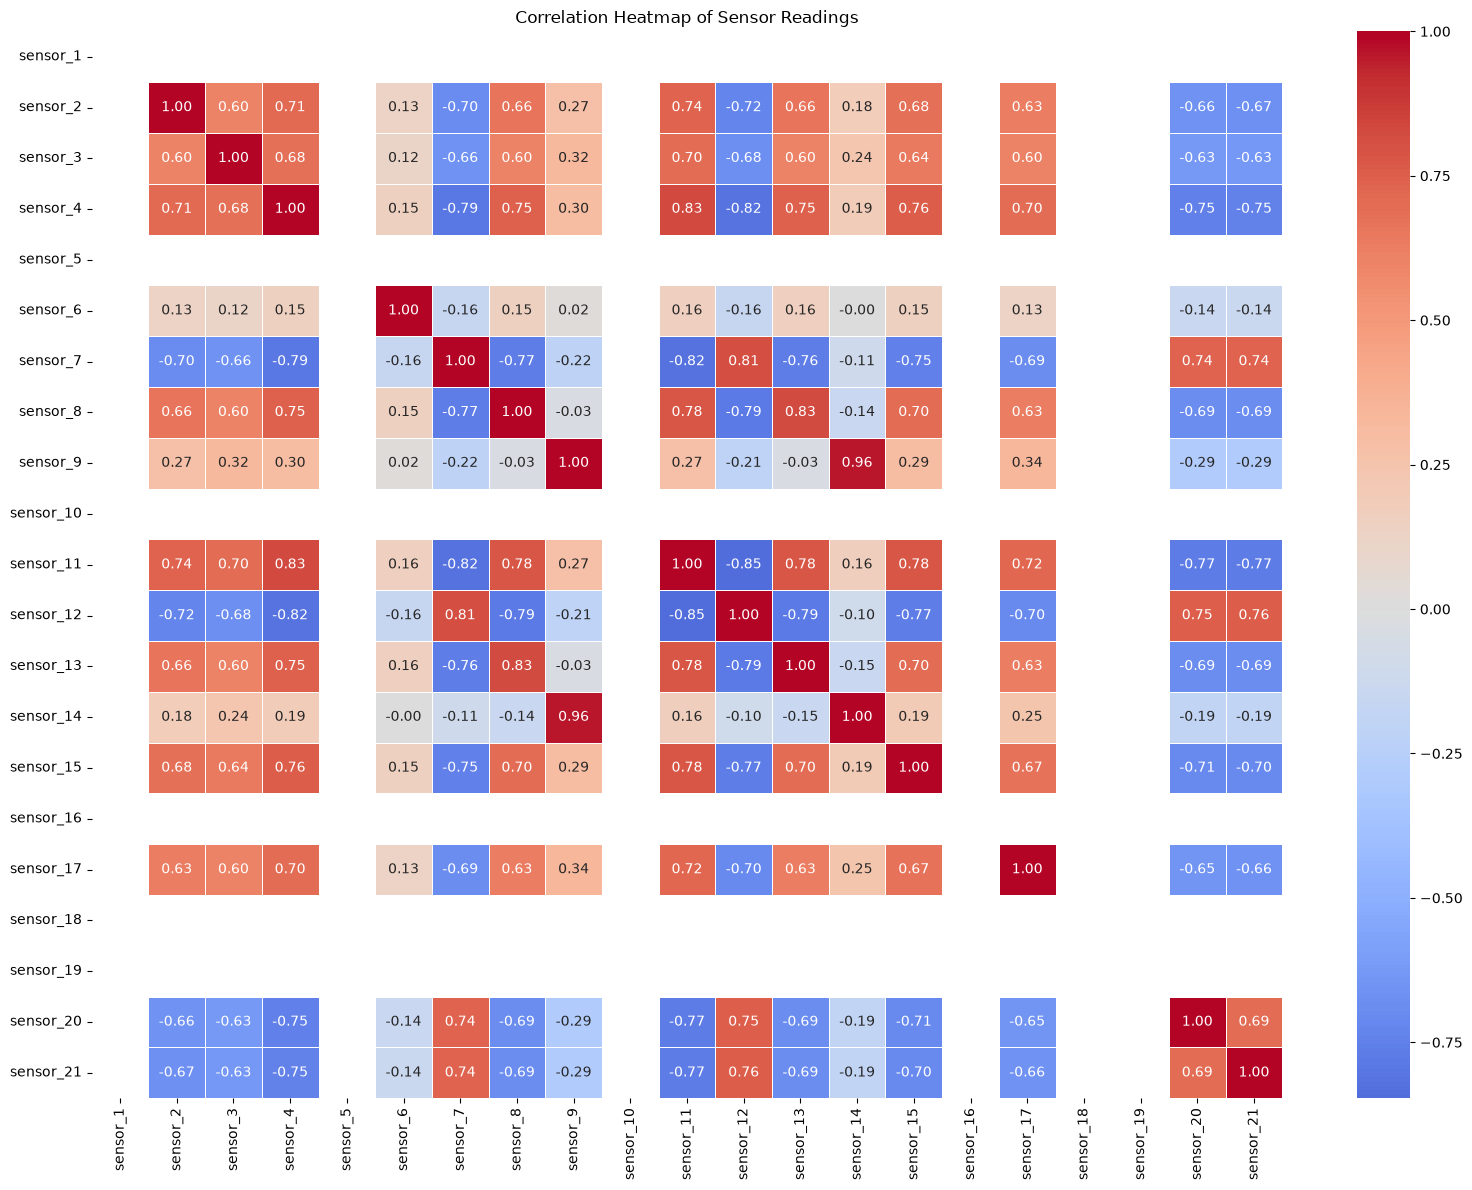

In [20]:
# Calculating correlation between all sensors
correlation_matrix = train[sensor_columns].corr()

# Creating correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Sensor Readings')
plt.tight_layout()
plt.show()


### Observations – Correlation Heatmap Analysis

1. Several sensor pairs exhibit strong positive correlations.
2. Sensor 9 and Sensor 14 show a very strong positive correlation of approximately 0.96.
3. Sensor 11 and Sensor 12 exhibit a strong negative correlation of approximately -0.85.
4. Sensor 20 and Sensor 21 show a positive correlation of approximately 0.69.
5. Constant sensors have undefined correlation values, resulting in blank areas in the heatmap.

**Conclusion:**

The correlation analysis reveals relationships between different sensor measurements. Some sensors provide highly correlated information, which may be relevant during feature selection.

Further analysis is required to determine whether these relationships are useful for predicting engine degradation.


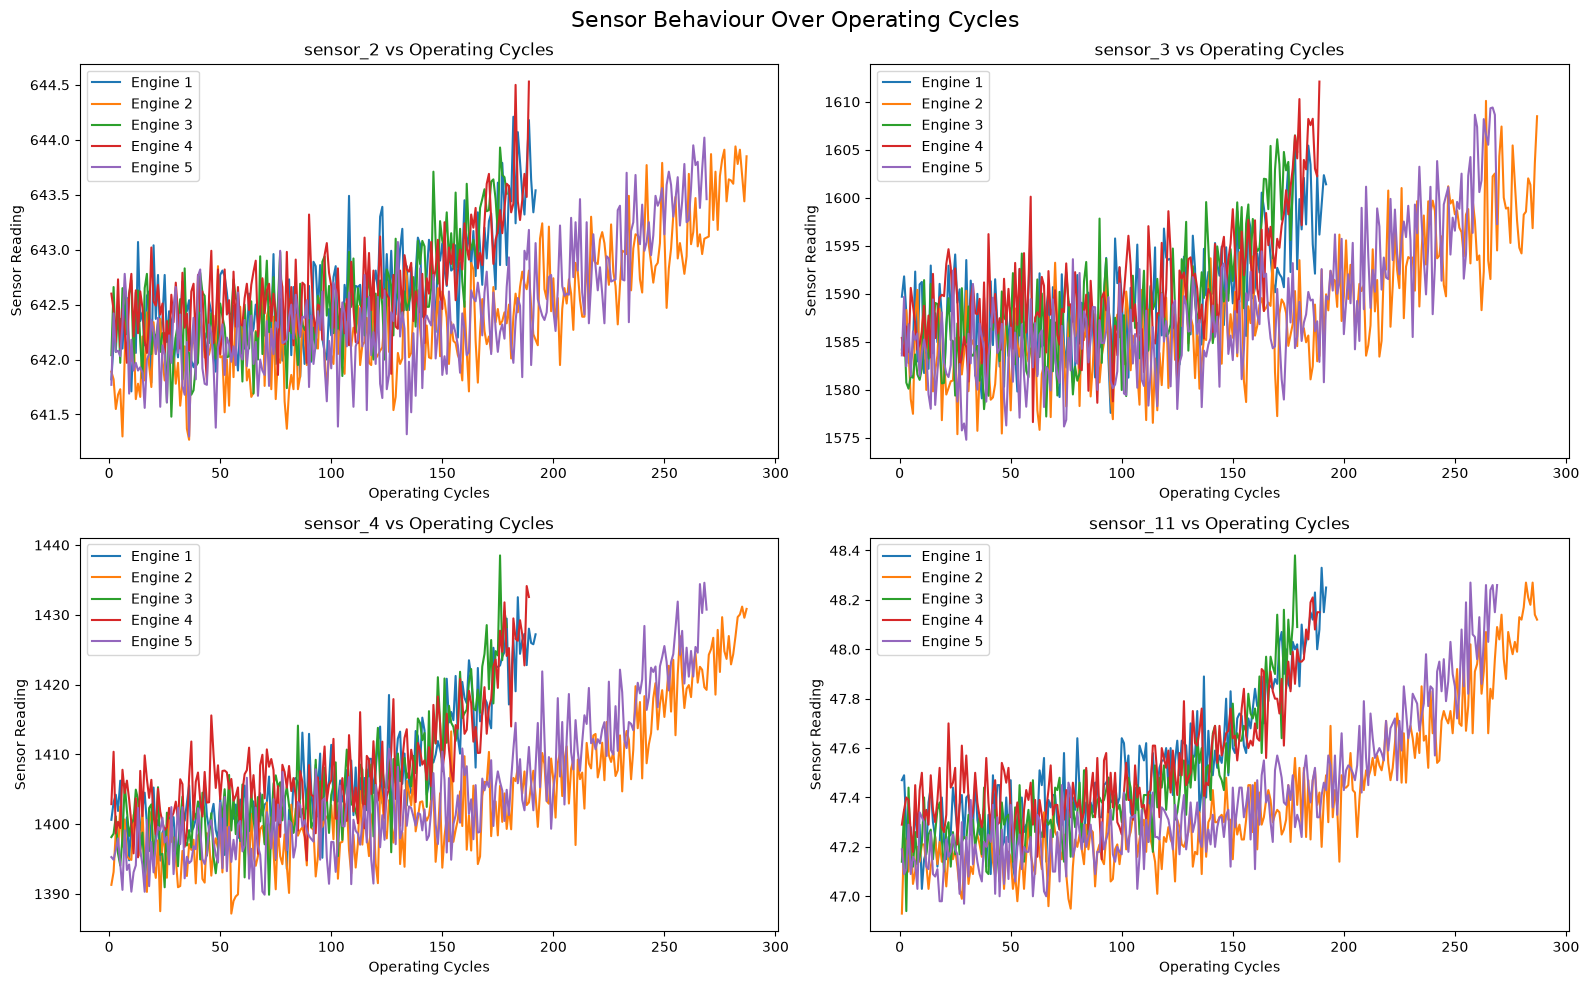

In [21]:
# Selecting sample engines
sample_engines = [1, 2, 3, 4, 5]

# Selecting sensors for visualization
selected_sensors = [
    'sensor_2',
    'sensor_3',
    'sensor_4',
    'sensor_11'
]

# Creating subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes = axes.flatten()

# Plotting sensor readings over operating cycles
for i, sensor in enumerate(selected_sensors):

    for engine_id in sample_engines:

        engine_data = train[
            train['engine_id'] == engine_id
        ]

        axes[i].plot(
            engine_data['cycle'],
            engine_data[sensor],
            label=f'Engine {engine_id}'
        )

    axes[i].set_title(f'{sensor} vs Operating Cycles')
    axes[i].set_xlabel('Operating Cycles')
    axes[i].set_ylabel('Sensor Reading')
    axes[i].legend()

plt.suptitle(
    'Sensor Behaviour Over Operating Cycles',
    fontsize=16
)

plt.tight_layout()
plt.show()


### Observations – Sensor Behaviour Over Operating Cycles

1. Sensor readings exhibit fluctuations throughout the operating cycles.
2. Sensors 2, 3, 4 and 11 show an overall increasing trend.
3. Sensor 4 and Sensor 11 show noticeable increases during later operating cycles.
4. Different engines exhibit different operating lifetimes and sensor behaviour.
5. Sensor readings do not increase perfectly monotonically, indicating variations in engine operating behaviour.

**Conclusion:**

Sensor readings change as operating cycles increase. These changing patterns may contain useful information about engine degradation and can be explored further for Remaining Useful Life prediction.


### Observations – Quantitative Outlier Detection

1. Sensor 9 has the highest number of potential outliers (1686).
2. Sensor 14 has the second-highest outlier count (1543).
3. Sensor 6 and Sensor 8 also contain comparatively higher outlier counts.
4. Sensors 1, 5, 10, 16, 18 and 19 have zero detected outliers because they exhibit constant readings.
5. Most remaining sensors have relatively fewer potential outliers.

**Conclusion:**

The IQR method identified different numbers of potential outliers across sensors. Sensor 9 and Sensor 14 have notably higher outlier counts.

However, these observations may represent genuine engine operating behaviour rather than incorrect data. Therefore, outlier removal will not be performed without further investigation.


In [24]:
# Creating sensor analysis summary

sensor_analysis = pd.DataFrame()

sensor_analysis['Sensor'] = sensor_columns

# Calculating standard deviation
sensor_analysis['Standard Deviation'] = [
    train[sensor].std() for sensor in sensor_columns
]

# Counting unique values
sensor_analysis['Unique Values'] = [
    train[sensor].nunique() for sensor in sensor_columns
]

# Calculating correlation with operating cycles
sensor_analysis['Cycle Correlation'] = [
    train[sensor].corr(train['cycle'])
    for sensor in sensor_columns
]

# Identifying constant and non-constant sensors
sensor_analysis['Status'] = sensor_analysis[
    'Unique Values'
].apply(
    lambda x: 'Constant' if x == 1 else 'Non-Constant'
)

# Sorting sensors by standard deviation
sensor_analysis = sensor_analysis.sort_values(
    by='Standard Deviation',
    ascending=False
)

sensor_analysis


,Sensor,Standard Deviation,Unique Values,Cycle Correlation,Status
8,sensor_9,2.208288e+01,6403,4.439993e-01,Non-Constant
13,sensor_14,1.907618e+01,6078,3.703236e-01,Non-Constant
3,sensor_4,9.000605e+00,4051,6.245772e-01,Non-Constant
2,sensor_3,6.131150e+00,3012,5.439470e-01,Non-Constant
16,sensor_17,1.548763e+00,13,5.669949e-01,Non-Constant
6,sensor_7,8.850923e-01,513,-5.959136e-01,Non-Constant
11,sensor_12,7.375534e-01,427,-6.113536e-01,Non-Constant
1,sensor_2,5.000533e-01,310,5.498980e-01,Non-Constant
10,sensor_11,2.670874e-01,159,6.343845e-01,Non-Constant
19,sensor_20,1.807464e-01,120,-5.835969e-01,Non-Constant


### Observations – Useful vs Irrelevant Sensor Identification

1. Six sensors (1, 5, 10, 16, 18 and 19) have constant readings and zero variance.
2. Sensor 11 and Sensor 4 show relatively strong positive correlations with operating cycles.
3. Sensors 12, 7, 20 and 21 show negative correlations with operating cycles.
4. Sensor 9 and Sensor 14 have the highest standard deviations among the sensors.
5. Sensor 6 has only two unique values and extremely low standard deviation, indicating very limited variation.
6. Sensor 17 has only 13 unique values but shows a moderate positive cycle correlation.

**Conclusion:**

The analysis identifies six constant sensors that can be considered for removal during preprocessing. Other sensors exhibit varying degrees of variation and relationships with operating cycles.

Further investigation is required before finalizing the useful sensor features for machine learning.


In [25]:
# Calculating maximum operating cycle for each engine

max_cycles = train.groupby('engine_id')['cycle'].max()

# Creating RUL column

train['RUL'] = train.apply(
    lambda row: max_cycles[row['engine_id']] - row['cycle'],
    axis=1
)

# Displaying sample data

train[['engine_id', 'cycle', 'RUL']].head(10)


,engine_id,cycle,RUL
0,1,1,191.0
1,1,2,190.0
2,1,3,189.0
3,1,4,188.0
4,1,5,187.0
5,1,6,186.0
6,1,7,185.0
7,1,8,184.0
8,1,9,183.0
9,1,10,182.0


In [26]:
constant_sensors = [
    'sensor_1', 'sensor_5', 'sensor_10',
    'sensor_16', 'sensor_18', 'sensor_19'
]

train_clean = train.drop(columns=constant_sensors).copy()

print("Original shape:", train.shape)
print("After removing constant sensors:", train_clean.shape)

Original shape: (20631, 27)
After removing constant sensors: (20631, 21)


In [27]:
print(train_clean.columns.tolist())

['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'RUL']


In [28]:
X = train_clean.drop(columns=['engine_id', 'RUL'])
y = train_clean['RUL']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20631, 19)
Target shape: (20631,)


In [29]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train_clean['engine_id'])
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Training engines:", train_clean.iloc[train_idx]['engine_id'].nunique())
print("Validation engines:", train_clean.iloc[val_idx]['engine_id'].nunique())

Training shape: (16561, 19)
Validation shape: (4070, 19)
Training engines: 80
Validation engines: 20


In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Linear Regression trained successfully
Random Forest trained successfully
Gradient Boosting trained successfully


In [31]:
print(models["Random Forest"])
print(models["Gradient Boosting"])

RandomForestRegressor(n_jobs=-1, random_state=42)
GradientBoostingRegressor(random_state=42)


In [32]:
for name, model in models.items():
    print(name, "—", hasattr(model, "n_features_in_"))

Linear Regression — True
Random Forest — True
Gradient Boosting — True


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

results = []

for name, model in models.items():
    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

               Model     MAE    RMSE  R2 Score
0  Linear Regression  25.155  31.656     0.768
1      Random Forest  24.086  31.758     0.766
2  Gradient Boosting  22.692  29.752     0.795


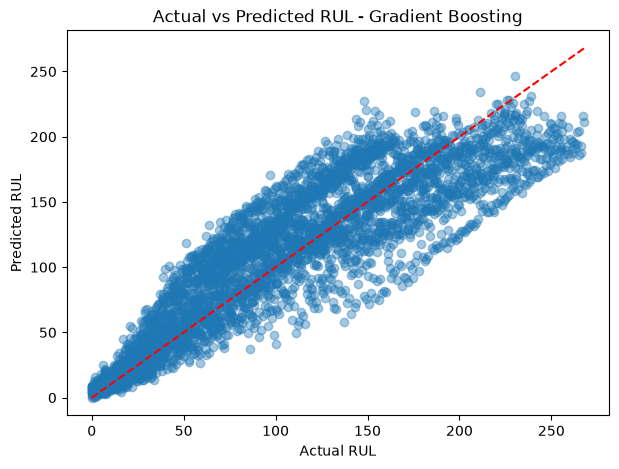

In [35]:
plt.figure(figsize=(7, 5))

plt.scatter(y_val, y_pred, alpha=0.4)

min_val = min(y_val.min(), y_pred.min())
max_val = max(y_val.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--'
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Gradient Boosting")
plt.show()

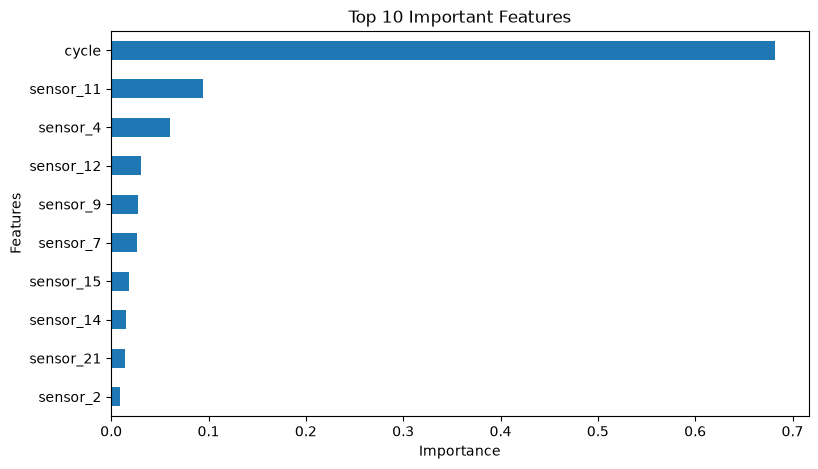

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
feature_importance.head(10).sort_values().plot(kind='barh')

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features")
plt.show()

In [37]:
import joblib

joblib.dump(best_model, "best_rul_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [38]:
joblib.dump(X_train.columns.tolist(), "feature_columns.pkl")

print("Feature columns saved successfully!")

Feature columns saved successfully!
